In [ ]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
from ISC_Helper import load_schaeffer1000

In [2]:
# Parameters
task = 'onesmallstep'
roi_selected = ['wholebrain']
emotions = ['P', 'N', 'M']
n_trs = 454
n_subj = 27
n_parcels = 1000

# File paths
base_dir = '/usr/people/ri4541/juke/isc'
scripts_path = f'{base_dir}/isc_scripts'
label_dir = f'{base_dir}/VideoLabelling'
data_path = f'{base_dir}/outputs/{task}/data'
figure_path = f'{base_dir}/outputs/{task}/figures'
isps_path = f'{data_path}/isps_{n_subj}subj_{n_parcels}parcels_{len(roi_selected)}rois.pkl'
mask_path = f'{data_path}/mask_img.npy'
parc_path = f'{scripts_path}/schaefer_2018/Schaefer2018_{n_parcels}Parcels_17Networks_order_FSLMNI152_2mm.nii.gz'

In [3]:
# Load ISPS and parcellation
with open(isps_path, 'rb') as f:
    isps_roi = pickle.load(f)
print('ISPS shapes:', {k: v.shape for k, v in isps_roi.items()})

parc, masked_parc = load_schaeffer1000(parc_path, mask_path)

ISPS shapes: {'wholebrain': (454, 1000)}


In [4]:
# Load behavioral labels and compute consensus (variance across subjects per TR)
coded_states = np.load(f'{label_dir}/coded_states_{task}_smooth.npy')  # (n_subj, TRs, n_emotions)
coded_states = coded_states[:, :-30]  # trim to n_trs=454
assert coded_states.shape[1] == n_trs
print('coded_states shape:', coded_states.shape)

# Variance across subjects at each TR = behavioral divergence (low = high consensus)
behav_consensus = np.var(coded_states[:, :n_trs, :3], axis=0)  # (n_trs, 3) — P, N, M
print('behav_consensus shape:', behav_consensus.shape)

coded_states shape: (27, 454, 5)
behav_consensus shape: (454, 3)


In [ ]:
from sklearn.linear_model import RidgeCV
from tqdm import tqdm

window_size, step_size = 30, 5
n_windows = (n_trs - window_size) // step_size + 1

isps = isps_roi['wholebrain']  # (n_trs, n_parcels)

# Window-averaged versions — used only for convergence comparison with sliding ISC (cells below)
isps_windowed = np.array([
    isps[i * step_size : i * step_size + window_size, :].mean(axis=0)
    for i in range(n_windows)
])  # (85, 1000)
slide_behav = np.array([
    behav_consensus[i * step_size : i * step_size + window_size].mean(axis=0)
    for i in range(n_windows)
])  # (85, 3)

# Main analysis: TR-resolution RidgeCV — predict isps from behav_consensus
alpha_range = np.logspace(-3, 3, 100)
true_coefs = np.empty((n_parcels, len(emotions)))
true_r2s = []

for parcel in tqdm(range(n_parcels)):
    model = RidgeCV(alphas=alpha_range, store_cv_values=True)
    model.fit(behav_consensus, isps[:, parcel])
    true_coefs[parcel] = model.coef_
    true_r2s.append(model.score(behav_consensus, isps[:, parcel]))

print(f'true_coefs: {true_coefs.shape}, mean R²: {np.mean(true_r2s):.4f}')

In [ ]:
from isc_standalone import p_from_null
from statsmodels.stats.multitest import multipletests

n_shifts = 1024
isps_perm_path = (
    f'{data_path}/sliding_isc/permutations/'
    f'phaseshift_size30_step5_{n_parcels}parcelsparcellated_{n_shifts}perms_{len(roi_selected)}rois_isps_x'
)
with open(isps_perm_path, 'rb') as f:
    x = pickle.load(f)
# x[roi] = [observed (n_trs, n_parcels), p, distribution (n_shifts, n_trs, n_parcels)]

distribution = x['wholebrain'][2]  # (n_shifts, n_trs, n_parcels)
print(f'distribution shape: {distribution.shape}')

# RidgeCV on each permutation at TR resolution — matches main analysis exactly
perm_coefs = np.empty((n_parcels, n_shifts, len(emotions)))
perm_r2s = np.empty((n_parcels, n_shifts))

for parcel in tqdm(range(n_parcels)):
    for perm in range(n_shifts):
        model = RidgeCV(alphas=alpha_range, store_cv_values=True)
        model.fit(behav_consensus, distribution[perm, :, parcel])
        perm_coefs[parcel, perm] = model.coef_
        perm_r2s[parcel, perm] = model.score(behav_consensus, distribution[perm, :, parcel])

print(f'perm_coefs shape: {perm_coefs.shape}')

In [ ]:
p_coef = np.empty((n_parcels, len(emotions)))
p_r2 = np.empty(n_parcels)

for parcel in range(n_parcels):
    for e in range(len(emotions)):
        p_coef[parcel, e] = p_from_null(true_coefs[parcel, e], perm_coefs[parcel, :, e])
    p_r2[parcel] = p_from_null(true_r2s[parcel], perm_r2s[parcel])

p_fdr = np.empty_like(p_coef)
for e in range(len(emotions)):
    _, q, _, _ = multipletests(p_coef[:, e], alpha=0.05, method='fdr_bh')
    p_fdr[:, e] = q

p_coef_thresholded = np.where(p_fdr < 0.05, true_coefs, 0)
for e, emo in enumerate(emotions):
    n_sig = (p_fdr[:, e] < 0.05).sum()
    print(f'{emo}: {n_sig} significant parcels (FDR < 0.05)')

In [ ]:
fig, axes = plt.subplots(len(emotions), 1, figsize=(14, 4 * len(emotions)), sharex=True)
for e, emo in enumerate(emotions):
    ax = axes[e]
    ax.bar(range(n_parcels), true_coefs[:, e], width=1.0, color='steelblue', alpha=0.5, label='Beta')
    sig_mask = p_fdr[:, e] < 0.05
    ax.scatter(np.where(sig_mask)[0], true_coefs[sig_mask, e],
               color='tomato', s=12, zorder=3, label=f'FDR < 0.05 (n={sig_mask.sum()})')
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_ylabel('Ridge \u03b2')
    ax.set_title(f'ISPS \u2192 behavior ridge beta \u2014 emotion {emo}')
    ax.legend(fontsize=8)
axes[-1].set_xlabel('Parcel index')
plt.tight_layout()
plt.savefig(f'{figure_path}/isps_behav_betas.png', dpi=150)
plt.show()

In [ ]:
import nibabel as nib

# FDR-corrected p-value map (4D)
img_p = np.zeros((*parc.shape, len(emotions)))
for p in range(1, n_parcels + 1):
    mask = parc.get_fdata() == p
    img_p[mask, :] = p_fdr[p - 1]
nib.save(nib.Nifti1Image(img_p, parc.affine),
         f'{data_path}/isps_emotion_pvals_corrected.nii.gz')

# Thresholded beta map (4D)
img_b = np.zeros((*parc.shape, len(emotions)))
for p in range(1, n_parcels + 1):
    mask = parc.get_fdata() == p
    img_b[mask, :] = p_coef_thresholded[p - 1]
nib.save(nib.Nifti1Image(img_b, parc.affine),
         f'{data_path}/isps_emotion_betas_corrected.nii.gz')

print('Saved isps_emotion_pvals_corrected.nii.gz')
print('Saved isps_emotion_betas_corrected.nii.gz')

Spearman r = 0.773, p = 1.47e-199


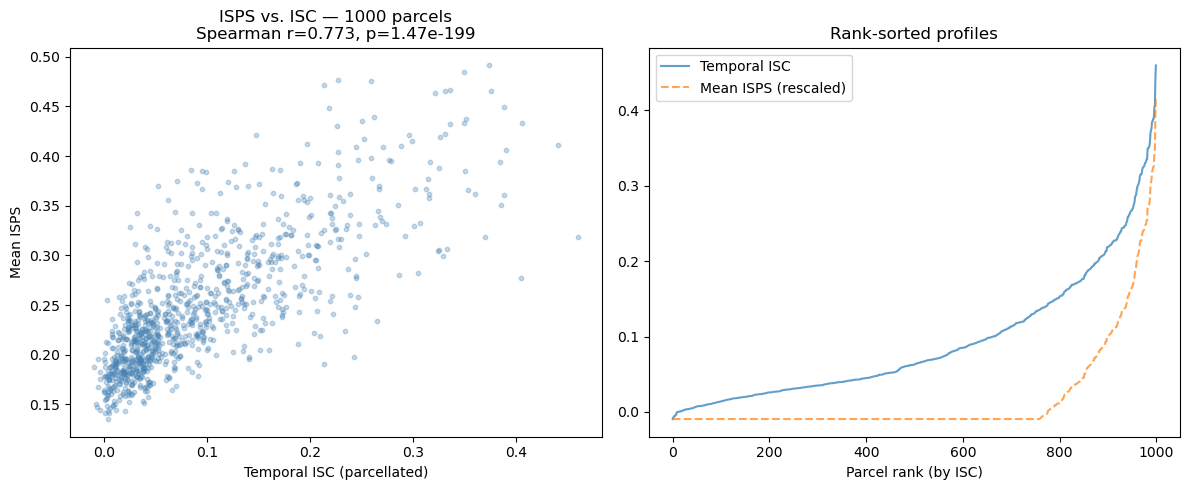

In [8]:
# Convergence: ISPS vs. temporal ISC across 1000 parcels
from scipy.stats import spearmanr

median_isc_vox = np.load(f'{data_path}/median_isc.npy')  # (n_voxels,)
isc_parcellated = np.array([median_isc_vox[masked_parc == p].mean() for p in range(1, n_parcels + 1)])
mean_isps = isps_roi[roi_selected[0]].mean(axis=0)  # (n_parcels,)

r, p = spearmanr(mean_isps, isc_parcellated)
print(f'Spearman r = {r:.3f}, p = {p:.2e}')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Scatter: one point per parcel
ax = axes[0]
ax.scatter(isc_parcellated, mean_isps, alpha=0.3, s=10, color='steelblue')
ax.set_xlabel('Temporal ISC (parcellated)')
ax.set_ylabel('Mean ISPS')
ax.set_title(f'ISPS vs. ISC — {n_parcels} parcels\nSpearman r={r:.3f}, p={p:.2e}')

# Sorted overlay: both measures ranked by ISC
ax = axes[1]
order = np.argsort(isc_parcellated)
ax.plot(isc_parcellated[order], label='Temporal ISC', alpha=0.7)
ax.plot(
    np.interp(isc_parcellated[order], [mean_isps.min(), mean_isps.max()],
              [isc_parcellated.min(), isc_parcellated.max()]),
    label='Mean ISPS (rescaled)', alpha=0.7, linestyle='--'
)
ax.set_xlabel('Parcel rank (by ISC)')
ax.set_title('Rank-sorted profiles')
ax.legend()

plt.tight_layout()
plt.savefig(f'{figure_path}/isps_vs_isc_convergence.png', dpi=150)
plt.show()

Per-parcel r: mean=0.005, median=0.001, std=0.214
All windows x parcels Spearman r=-0.005


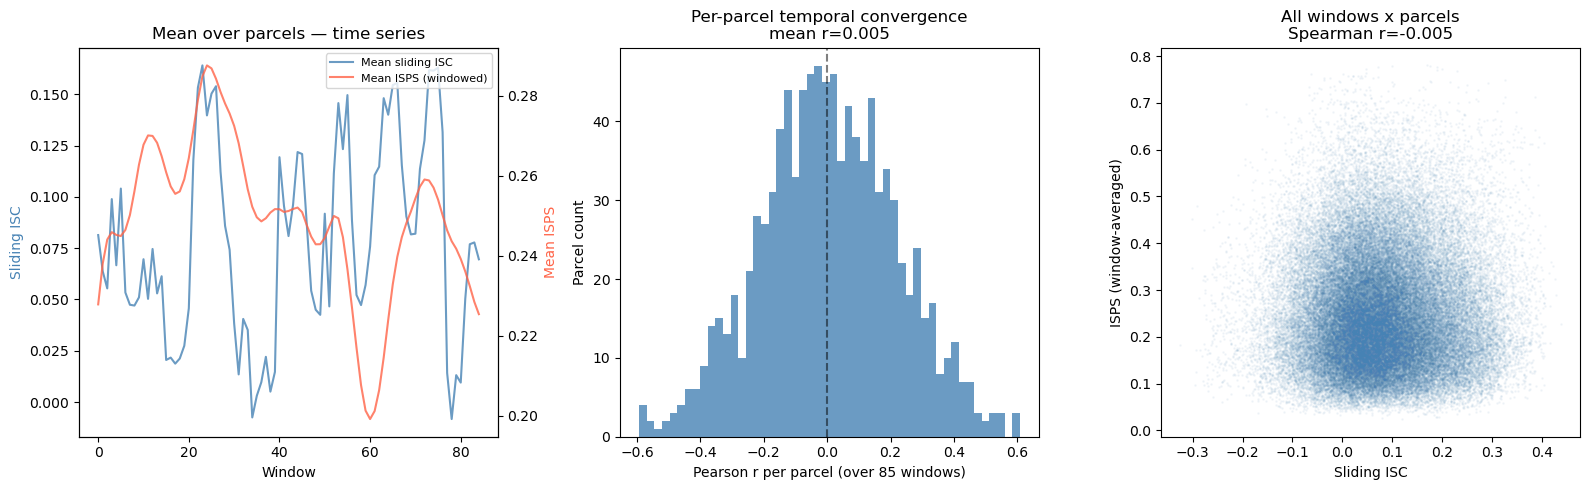

In [9]:
# Convergence: ISPS vs. sliding ISC (temporal comparison)
from scipy.stats import spearmanr

window_size, step_size = 30, 5
n_windows = (n_trs - window_size) // step_size + 1

sliding_isc_path = (
    f'{data_path}/sliding_isc/permutations/'
    f'phaseshift_size30_step5_1000parcelsparcellated_10240perms_1rois_x'
)
with open(sliding_isc_path, 'rb') as f:
    sliding_x = pickle.load(f)
observed_isc = sliding_x['wholebrain'][0]  # (n_windows, n_parcels)

# Window-average ISPS to match sliding ISC temporal resolution
isps = isps_roi['wholebrain']  # (n_trs, n_parcels)
isps_windowed = np.array([
    isps[i * step_size : i * step_size + window_size, :].mean(axis=0)
    for i in range(n_windows)
])  # (n_windows, n_parcels)

# Per-parcel temporal correlation over windows
from scipy.stats import pearsonr
parcel_r = np.array([pearsonr(observed_isc[:, p], isps_windowed[:, p])[0] for p in range(n_parcels)])
r_all, _ = spearmanr(observed_isc.ravel(), isps_windowed.ravel())
print(f'Per-parcel r: mean={parcel_r.mean():.3f}, median={np.median(parcel_r):.3f}, std={parcel_r.std():.3f}')
print(f'All windows x parcels Spearman r={r_all:.3f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Time series: mean over parcels
ax = axes[0]
ax2 = ax.twinx()
ax.plot(observed_isc.mean(axis=1), color='steelblue', alpha=0.8, label='Mean sliding ISC')
ax2.plot(isps_windowed.mean(axis=1), color='tomato', alpha=0.8, label='Mean ISPS (windowed)')
ax.set_xlabel('Window')
ax.set_ylabel('Sliding ISC', color='steelblue')
ax2.set_ylabel('Mean ISPS', color='tomato')
ax.set_title('Mean over parcels — time series')
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper right', fontsize=8)

# Per-parcel temporal r histogram
ax = axes[1]
ax.hist(parcel_r, bins=50, color='steelblue', alpha=0.8)
ax.axvline(0, color='black', linestyle='--', alpha=0.5)
ax.set_xlabel('Pearson r per parcel (over 85 windows)')
ax.set_ylabel('Parcel count')
ax.set_title(f'Per-parcel temporal convergence\nmean r={parcel_r.mean():.3f}')

# Scatter: all (window, parcel) pairs
ax = axes[2]
ax.scatter(observed_isc.ravel(), isps_windowed.ravel(), alpha=0.05, s=1, color='steelblue')
ax.set_xlabel('Sliding ISC')
ax.set_ylabel('ISPS (window-averaged)')
ax.set_title(f'All windows x parcels\nSpearman r={r_all:.3f}')

plt.tight_layout()
plt.savefig(f'{figure_path}/isps_vs_sliding_isc_convergence.png', dpi=150)
plt.show()

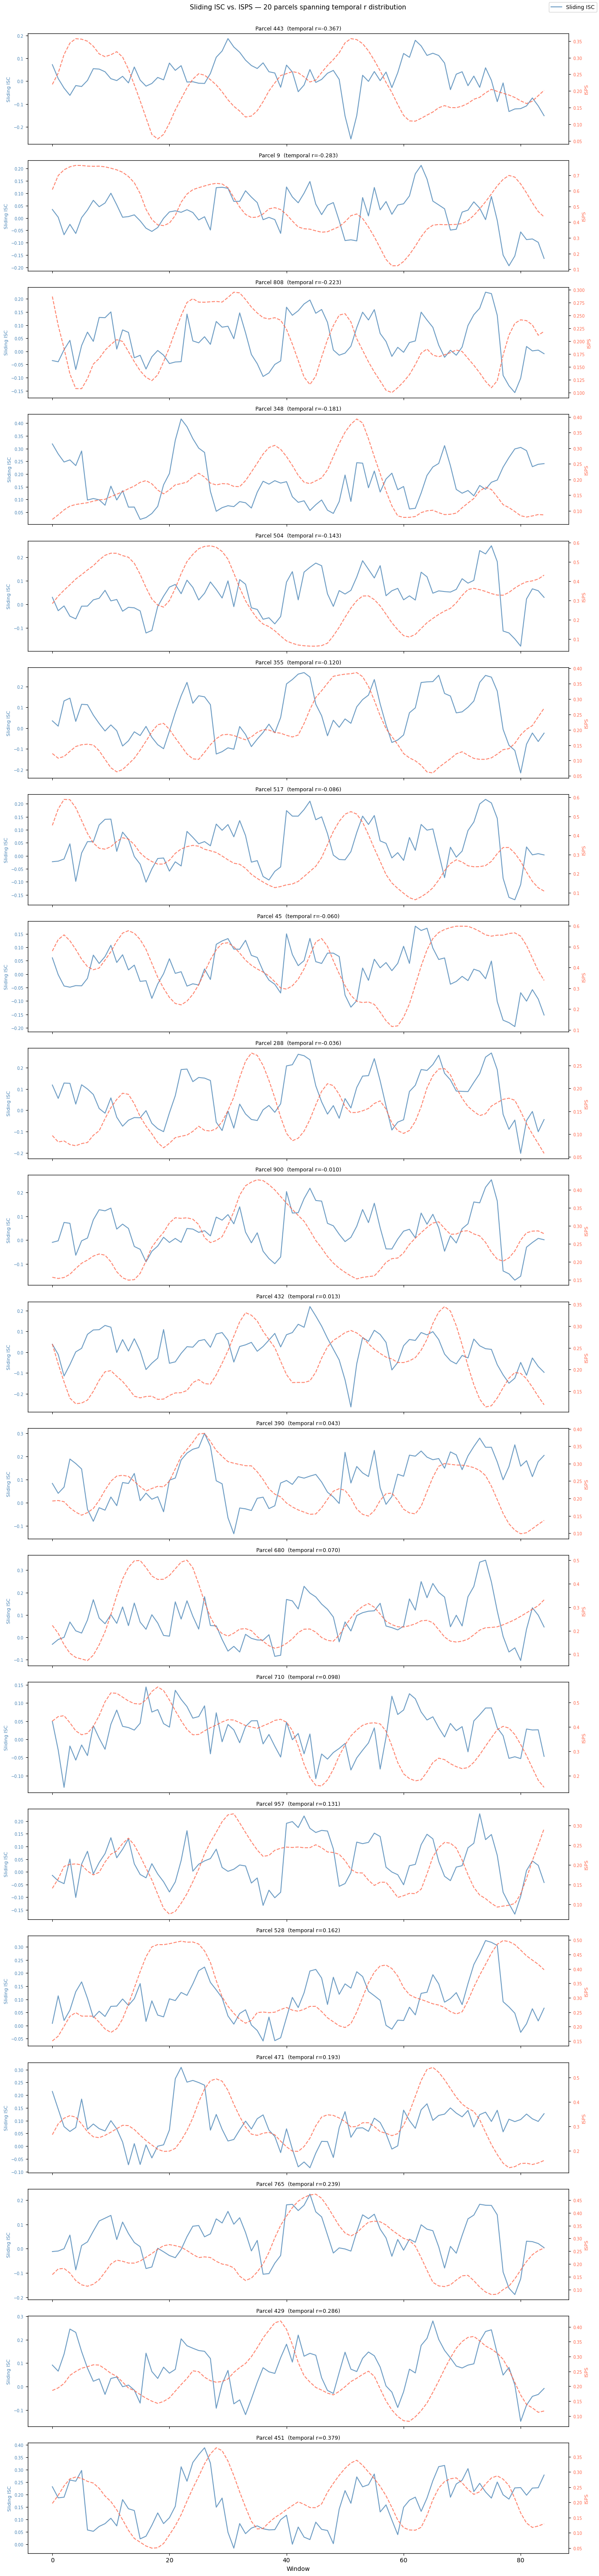

In [10]:
# Per-parcel timecourses: sliding ISC vs. window-averaged ISPS
n_show = 20
quantiles = np.linspace(0, 1, n_show + 2)[1:-1]
selected_parcels = [int(np.argsort(parcel_r)[int(q * n_parcels)]) for q in quantiles]

fig, axes = plt.subplots(n_show, 1, figsize=(14, 3 * n_show), sharex=True)
for ax, p in zip(axes, selected_parcels):
    ax2 = ax.twinx()
    ax.plot(observed_isc[:, p], color='steelblue', alpha=0.8, label='Sliding ISC')
    ax2.plot(isps_windowed[:, p], color='tomato', alpha=0.8, linestyle='--', label='ISPS')
    ax.set_title(f'Parcel {p}  (temporal r={parcel_r[p]:.3f})', fontsize=9)
    ax.set_ylabel('Sliding ISC', color='steelblue', fontsize=8)
    ax2.set_ylabel('ISPS', color='tomato', fontsize=8)
    ax.tick_params(axis='y', labelcolor='steelblue', labelsize=7)
    ax2.tick_params(axis='y', labelcolor='tomato', labelsize=7)

axes[-1].set_xlabel('Window')
lines1, labels1 = axes[0].get_legend_handles_labels()
fig.legend(lines1, labels1, loc='upper right', fontsize=9)

fig.suptitle(f'Sliding ISC vs. ISPS — {n_show} parcels spanning temporal r distribution', fontsize=11, y=1.001)
plt.tight_layout()
plt.savefig(f'{figure_path}/isps_vs_sliding_isc_parcels.png', dpi=150, bbox_inches='tight')
plt.show()

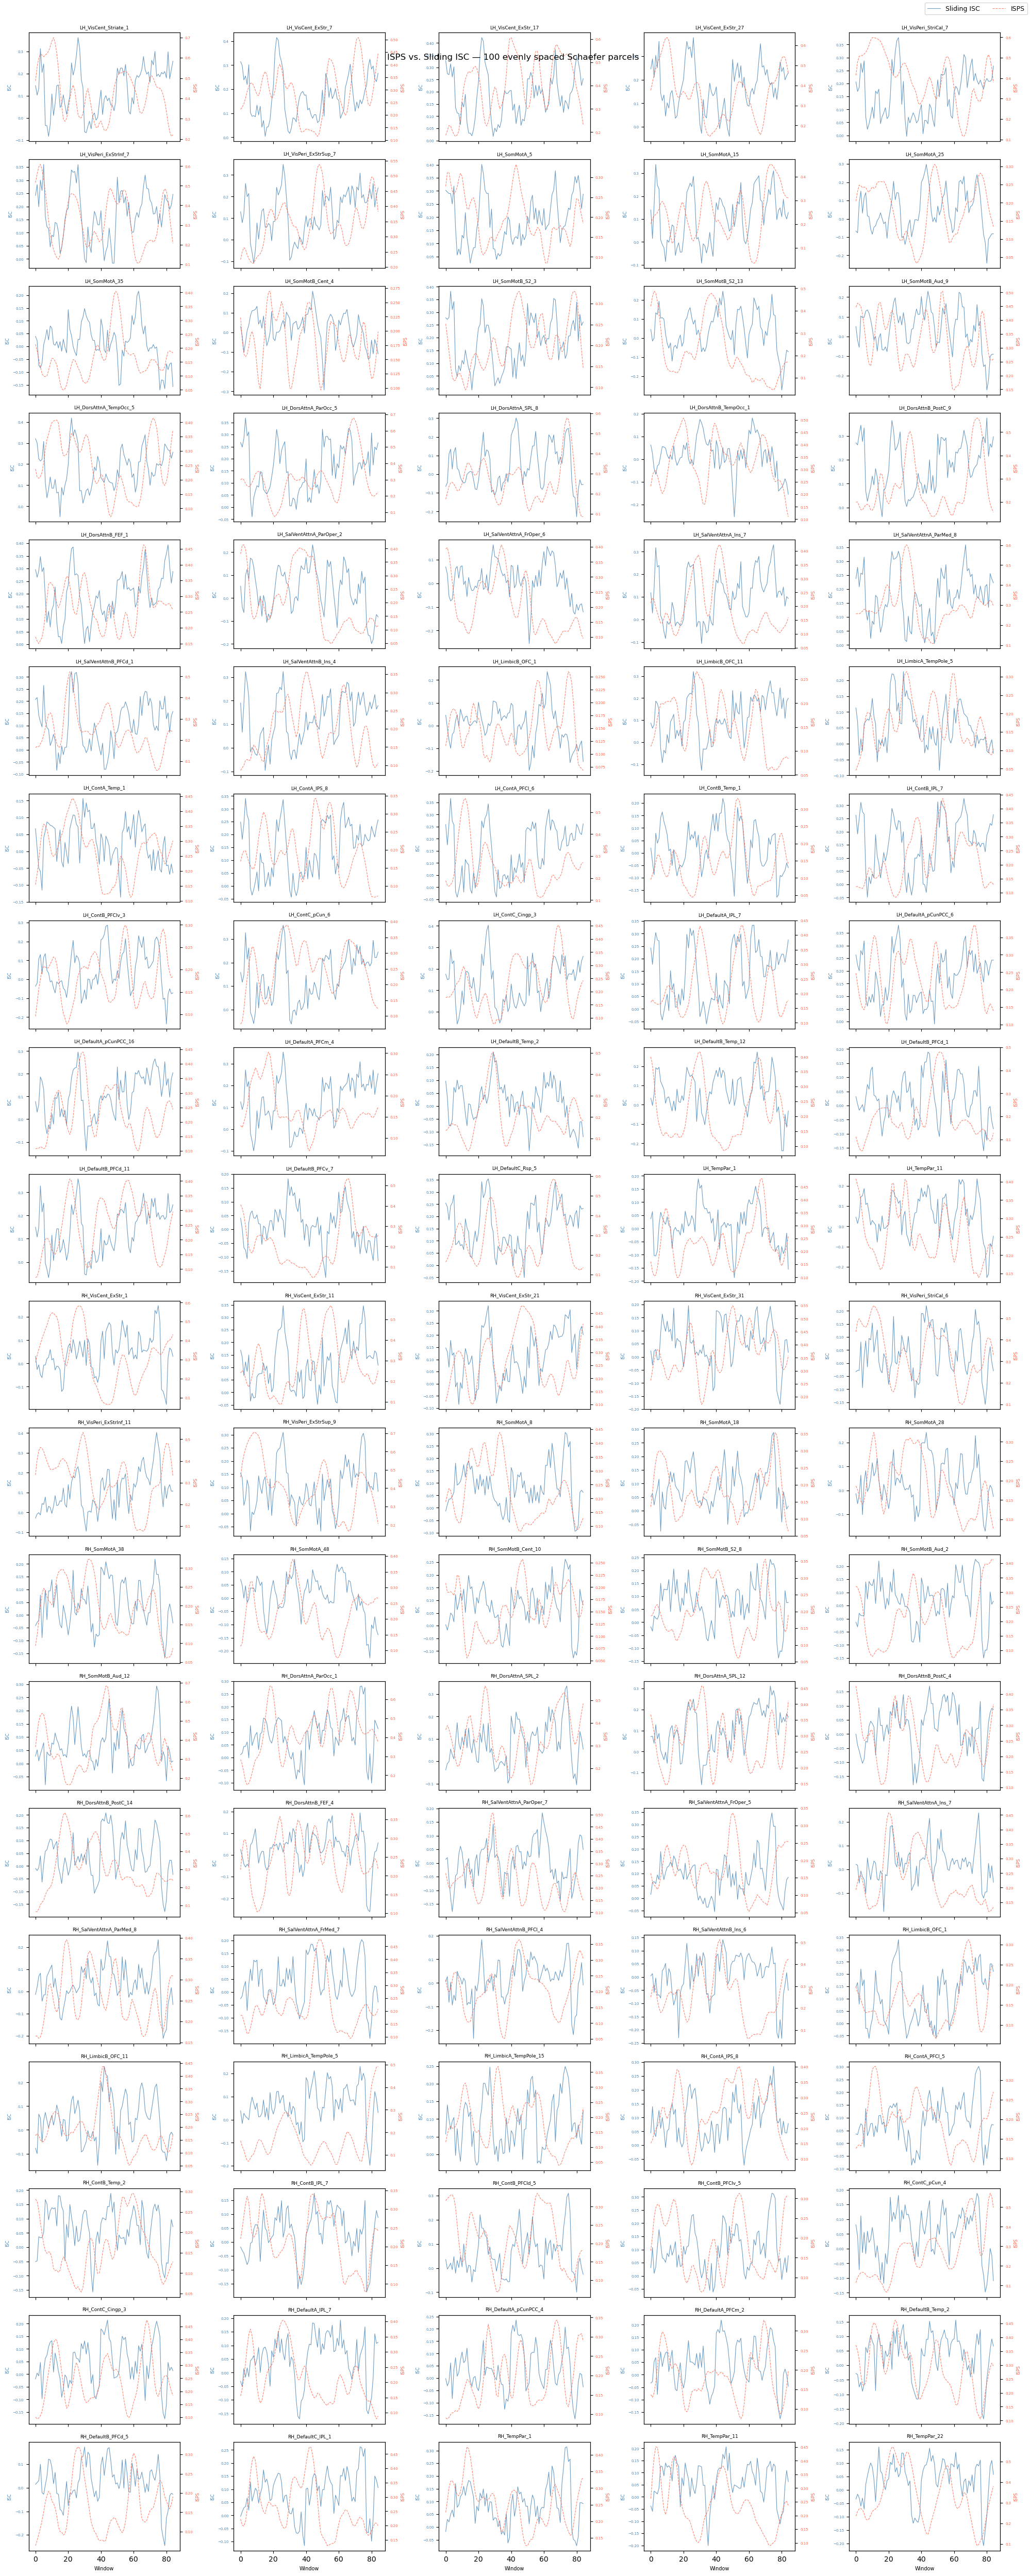

In [11]:
# ISPS + sliding ISC timecourses for evenly spaced parcels, named by Schaefer atlas
n_rows, n_cols = 20, 5
n_show = n_rows * n_cols
selected_parcels = np.linspace(0, n_parcels - 1, n_show, dtype=int)

# Load parcel names (1-based in file → 0-based index in array)
label_path = f'{scripts_path}/schaefer_2018/Schaefer2018_1000Parcels_17Networks_order.txt'
parcel_names = np.genfromtxt(label_path, dtype=str, usecols=1)
parcel_names = [n.replace('17Networks_', '') for n in parcel_names]

isps = isps_roi['wholebrain']  # (n_trs, n_parcels)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 2.5), sharex=True)
for ax, p in zip(axes.ravel(), selected_parcels):
    ax2 = ax.twinx()
    ax.plot(observed_isc[:, p], color='steelblue', linewidth=0.8, alpha=0.8, label='Sliding ISC')
    ax2.plot(isps_windowed[:, p], color='tomato', linewidth=0.8, alpha=0.8, linestyle='--', label='ISPS')
    ax.set_title(parcel_names[p], fontsize=6.5)
    ax.set_ylabel('ISC', color='steelblue', fontsize=6)
    ax2.set_ylabel('ISPS', color='tomato', fontsize=6)
    ax.tick_params(axis='y', labelcolor='steelblue', labelsize=5)
    ax2.tick_params(axis='y', labelcolor='tomato', labelsize=5)

for ax in axes[-1]:
    ax.set_xlabel('Window', fontsize=7)

# Legend on first subplot
h1, l1 = axes[0, 0].get_legend_handles_labels()
h2, l2 = axes[0, 0].get_shared_x_axes().get_siblings(axes[0, 0])[-1].get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc='upper right', fontsize=9, ncol=2)

fig.suptitle(f'ISPS vs. Sliding ISC — {n_show} evenly spaced Schaefer parcels', fontsize=12)
plt.tight_layout()
plt.savefig(f'{figure_path}/isps_vs_sliding_isc_parcels.png', dpi=150, bbox_inches='tight')
plt.show()